### **Student Information**
GitHub ID:

Kaggle name:

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

**Syntax:** `#` creates the largest heading (H1).

---
**Syntax:** `---` creates a horizontal rule (a separator line).

## 1. Model Development (10 pts Required)

**Syntax:** `##` creates a secondary heading (H2).

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

**Syntax:** `###` creates a tertiary heading (H3).

[Content for Preprocessing]

**Example Syntax for Content:**
*   **Bold text:** `**text**`
*   *Italic text*: `*text*`
*   Bullet point list:
    * Item 1
    * Item 2

Markdown Syntax to Add Image: `![Description of the Image](./your_local_folder/name_of_the_image.png)`

![Example Markdown Syntax to Add Image](./pics/example_md_img.png)

### 1.2 Feature Engineering Steps

[Content for Feature Engineering]

### 1.3 Explanation of Your Model

[Content for Model Explanation]

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

[Content for AI Prompts and your reason]

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

### 1.1 Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import html

# NLTK
import re
import collections
import nltk
nltk.download("stopwords")
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split

LABELS = ["joy", "anger", "sadness", "disgust", "surprise", "fear"]
SEED = 42

[nltk_data] Downloading package stopwords to /home/enarde/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 1.2 Data Loading

In [2]:
### Add the code related to the preprocessing steps in cells inside this section
DATA_DIR = "data/kaggle"

# Load the raw files
posts = pd.read_json(f"{DATA_DIR}/final_posts.json")
split = pd.read_csv(f"{DATA_DIR}/data_identification.csv")
labels = pd.read_csv(f"{DATA_DIR}/emotion.csv")

# Join on post_id
df = posts.merge(split, on="post_id").merge(labels, on="post_id", how="left")

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)

print(train_df.shape, test_df.shape) # (3360, 4) (1440, 4)
print(train_df["label"].value_counts())
train_df.head()

(3360, 4) (1440, 4)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness
3,9u6wtvm,The pottery around Brasov is in danger,train,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",train,fear


In [3]:
# Missing labels for test data is expected
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("shape:", d.shape)
    print("missing values per column:")
    print(d.isna().sum())
    print()

--- train ---
shape: (3360, 4)
missing values per column:
post_id    0
text       0
set        0
label      0
dtype: int64

--- test ---
shape: (1440, 4)
missing values per column:
post_id       0
text          0
set           0
label      1440
dtype: int64



In [4]:
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("Column data types:")
    print(d.dtypes)
    print()
    print("Duplicate ids:")
    print(d["post_id"].duplicated().sum())
    print("Duplicate texts:")
    print(d["text"].duplicated().sum())
    print("Duplicate texts with same label:")
    print(d.duplicated(subset=["text", "label"]).sum())
    print()
    print("Unique emotion labels:")
    for emotion in d['label'].unique():
        print(emotion)
    print()

print("Number of texts appearing in both train and test:")
shared = set(train_df["text"]) & set(test_df["text"])
print(len(shared))

--- train ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
50
Duplicate texts with same label:
34

Unique emotion labels:
disgust
sadness
fear
joy
anger
surprise

--- test ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
8
Duplicate texts with same label:
8

Unique emotion labels:
nan

Number of texts appearing in both train and test:
59


In [5]:
# remove duplicates from training data
train_df = train_df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
print("Duplicate texts with same label (Training):")
print(train_df.duplicated(subset=["text", "label"]).sum())

Duplicate texts with same label (Training):
0


### Exploration of contents

In [6]:
# Check the most common characters used in the texts
chars = collections.Counter(ch for s in train_df.text for ch in s
                            if not ch.isalnum() and not ch.isspace())
chars.most_common(40)

[('.', 3120),
 (',', 2773),
 ("'", 1530),
 ('!', 591),
 ('?', 346),
 (']', 274),
 ('[', 273),
 ('’', 259),
 ('>', 194),
 ('"', 186),
 ('-', 178),
 ('<', 176),
 (':', 175),
 ('@', 175),
 ('#', 133),
 ('*', 83),
 (')', 81),
 ('😂', 62),
 ('(', 53),
 ('/', 53),
 ('😭', 47),
 (';', 30),
 ('️', 29),
 ('”', 20),
 ('“', 19),
 ('%', 13),
 ('♪', 13),
 ('^', 12),
 ('🥰', 11),
 ('🙏', 11),
 ('❤', 10),
 ('😁', 10),
 ('🤣', 10),
 ('~', 8),
 ('👏', 7),
 ('🤔', 7),
 ('$', 6),
 ('+', 5),
 ('♂', 5),
 ('🙄', 4)]

In [7]:
# Identify commonly occurring templates and patterns in the text
def shape(w):
    w = re.sub(r"\d+", "9", w)
    w = re.sub(r"[A-Z]+", "A", w)
    return re.sub(r"[a-z]+", "a", w)

odd = [w for s in train_df.text for w in s.split() if re.search(r"[^\w'.,!?\"’]", w)]
collections.Counter(shape(w) for w in odd).most_common(30)

[('[A]', 201),
 ('@<a>', 172),
 ('Aa:', 67),
 ('a-a', 42),
 ('a:', 33),
 ('-', 32),
 ('[A].', 30),
 ('a;', 23),
 ('[A],', 20),
 ('a/a', 19),
 ('(a', 15),
 ('♪', 13),
 ('##A###', 11),
 ('a)', 11),
 (':)', 11),
 ('*a*', 10),
 (':(', 10),
 ('Aa-Aa', 10),
 ('#a', 10),
 ('>', 9),
 ('a*', 9),
 ('#Aa', 8),
 ('9%', 8),
 ('##A##', 7),
 ('a”', 7),
 ('“a', 6),
 ('a-a,', 6),
 ('a).', 6),
 ('*a', 6),
 ('*Aa', 6)]

In [8]:
# List bracketed or marked words in the texts
collections.Counter(re.findall(r"[\[<{#][\w#]+[\]>}#]*", " ".join(train_df.text))).most_common(20)

[('[NAME]', 270),
 ('<username>', 173),
 ('##URL###', 11),
 ('##URL##', 7),
 ('#RwOT', 3),
 ('<3', 2),
 ('#Famille', 1),
 ('##URL####', 1),
 ('#PLAY', 1),
 ('#CHOGM2022', 1),
 ('#Pizzets', 1),
 ('#Fact', 1),
 ('#1', 1),
 ('[Think]', 1),
 ('#HorrorBaro', 1),
 ('#VfB', 1),
 ('#likeapig', 1),
 ('#Alert', 1),
 ('#blessingswe', 1),
 ('#oromoliberationarmy', 1)]

### 1.3 Data Cleaning & Standardizing

In [9]:
def clean_text(text):
    # Decode HTML entities first (&amp; -> &), so later rules see real characters
    text = html.unescape(text)

    # Remove invisible emoji modifiers, so ❤️ and ❤ become the same token
    text = text.replace("\ufe0f", "").replace("\u200d", "")

    # Strip HTML tags like <li>, <i>, </b>. The (?!username>) part skips
    #    <username>, which is handled in the next rule
    text = re.sub(r"<(?!username>)/?[a-zA-Z]+\s*/?>", " ", text)

    # Placeholders -> consistent tokens
    text = re.sub(r"@<username>|@\w+", " USERTOKEN ", text)
    text = re.sub(r"#*\bURL\b#*|https?://\S+|www\.\S+", " URLTOKEN ", text) # all ##URL### variants
    text = re.sub(r"\[NAME\]", " NAMETOKEN ", text)
    text = re.sub(r"\[RELIGION\]", " RELIGIONTOKEN ", text)
    text = re.sub(r"\b[ru]/\w+", " REDDITTOKEN ", text)

    # Reddit formatting: keep the words, drop the markup
    text = re.sub(r"^\s*>+\s*", "", text)          # quote marker at the start of a post
    text = re.sub(r"~~(.+?)~~", r"\1", text)       # ~~strikethrough~~
    text = re.sub(r"\*+([^*]+?)\*+", r"\1", text)  # *action* and **bold**

    # Music notes mark lyrics or singing
    text = re.sub(r"♪+", " MUSICTOKEN ", text)

    # Hashtags: keep the word, drop the '#'. This runs after the URL rule
    #    so ##URL## isn't damaged
    text = re.sub(r"#(\w+)", r"\1", text)

    # Curly quotes -> straight quotes, then collapse whitespace
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", text).strip()

In [10]:
# TweetTokenizer keeps emoji and contractions, and shortens "sooooo" to "sooo"
tok = TweetTokenizer(preserve_case=False, reduce_len=True)

# Keep negations: removing "not" turns "not happy" into "happy"
NEGATIONS = {"no", "not", "nor", "never", "don't", "didn't", "isn't", "wasn't",
             "can't", "won't", "shouldn't", "couldn't", "doesn't", "aren't"}
STOP = set(stopwords.words("english")) - NEGATIONS

def tokenize(text, remove_stop=False):
    toks = tok.tokenize(text)
    if remove_stop:
        toks = [t for t in toks if t not in STOP]
    return toks

train_df["clean_text"] = train_df["text"].map(clean_text)
train_df["tokens"] = train_df["clean_text"].map(tokenize)
test_df["clean_text"] = test_df["text"].map(clean_text)
test_df["tokens"] = test_df["clean_text"].map(tokenize)

In [11]:
# Most common tokenizer outputs
collections.Counter(x for s in train_df.text for x in tokenize(clean_text(s))
                    if not re.fullmatch(r"[A-Za-z']+|[.,!?\"]+", x)).most_common(30)

[(':', 129),
 ('-', 69),
 (')', 64),
 ('😂', 54),
 ('(', 40),
 ('/', 39),
 ('😭', 37),
 (';', 29),
 (':)', 15),
 ('%', 13),
 ('^', 12),
 (':(', 11),
 ('*', 11),
 ('2', 10),
 ('19', 10),
 ('3', 10),
 ('8', 10),
 ('🥰', 10),
 ('❤', 10),
 ('🙏', 10),
 ('🤣', 10),
 ('30', 9),
 ('1', 9),
 ('😁', 9),
 ('100', 7),
 ('10', 7),
 ('👏', 7),
 ('20', 7),
 ('🤔', 7),
 ('4', 6)]

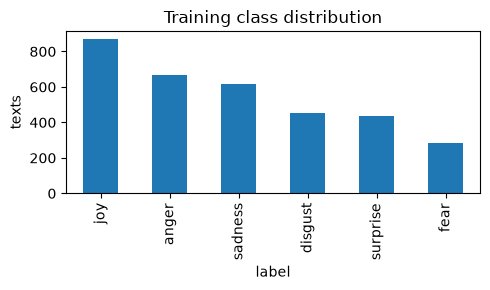

In [12]:
fig, ax = plt.subplots(figsize=(5, 3))
train_df["label"].value_counts().reindex(LABELS).plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Training class distribution"); ax.set_ylabel("texts")
plt.tight_layout(); plt.show()

          count  mean   std  min   25%   50%   75%    max
label                                                    
anger     667.0  20.3  36.5  2.0   9.0  14.0  22.0  509.0
disgust   451.0  18.7  28.9  1.0   9.0  14.0  22.0  506.0
fear      282.0  17.1  17.5  3.0   9.0  15.0  21.0  242.0
joy       870.0  20.4  36.2  2.0   9.0  14.0  21.0  508.0
sadness   619.0  18.2  20.6  1.0  10.0  15.0  21.0  387.0
surprise  437.0  14.9   8.5  2.0   9.0  14.0  19.0   79.0


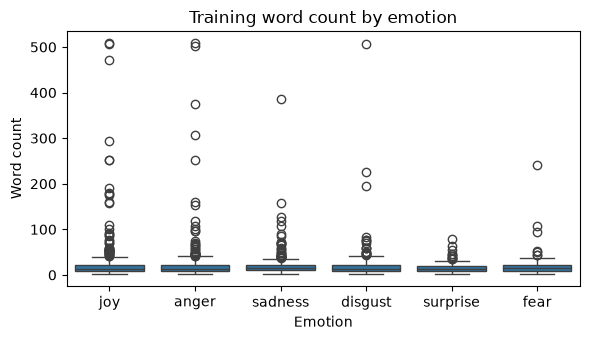

In [13]:
# Text length, counted in tokens, summarized per emotion.
train_df["word_count"] = train_df["tokens"].map(len)
print(train_df.groupby("label")["word_count"].describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))

sns.boxplot(data=train_df, x="label", y="word_count",order=LABELS, ax=ax)
ax.set_title("Training word count by emotion")
ax.set_xlabel("Emotion")
ax.set_ylabel("Word count")

plt.tight_layout()
plt.show()

In [14]:
# Unique-token ratio: share of tokens in a post that are distinct (low = repetition loop)
train_df["unique_ratio"] = train_df["tokens"].map(lambda t: len(set(t)) / len(t))

N_PER_LABEL = 3
PREVIEW_CHARS = 200

# Sort by length, keep the N longest per label, then order by label for display
longest = (train_df.sort_values("word_count", ascending=False)
                   .groupby("label", sort=False)
                   .head(N_PER_LABEL)
                   .sort_values(["label", "word_count"], ascending=[True, False]))

for label, group in longest.groupby("label"):
    print(f"\n=== {label.upper()} ===")
    for _, row in group.iterrows():
        flag = "LOOP" if row.unique_ratio < 0.3 else "    "
        print(f"[{flag}] {row.word_count:4d} tokens | unique {row.unique_ratio:.0%} | "
              f"{row.clean_text[:PREVIEW_CHARS]}...")


=== ANGER ===
[LOOP]  509 tokens | unique 4% | I was really shy, in the first place, when I was in charge of the cargo, and I was really in charge of the cargo, and I was in the kitchen, and I was in the kitchen, and I was in the kitchen, and I wa...
[LOOP]  502 tokens | unique 6% | Today 2014 democracy scholars who are waiting for you see you waiting for you Habiba Siraj omn conscience is fighting and we are waiting for the truth in our lives we are afraid of life and we are for...
[LOOP]  375 tokens | unique 5% | The world is a terrible place to live if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it i...

=== DISGUST ===
[LOOP]  506 tokens | unique 4% | I'm wearing a suit and I'm learning Somali. Oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, ...
[LOOP]  226 tokens |

In [15]:
def collapse_repeats(tokens, max_n=10, max_copies=2):
    """Collapse a phrase of 1..max_n tokens repeated back-to-back into at most max_copies."""
    out = list(tokens)
    for n in range(1, max_n + 1):
        i, res = 0, []
        while i < len(out):
            chunk = out[i:i + n]
            copies = 1
            while len(chunk) == n and out[i + copies * n:i + (copies + 1) * n] == chunk:
                copies += 1
            if copies > 1:
                res.extend(chunk * min(copies, max_copies))
                i += n * copies
            else:
                res.append(out[i])
                i += 1
        out = res
    return out

In [16]:
# Unstratified: rows are shuffled and split at random
tr_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED)
tr_y = tr_df["label"]
val_y = val_df["label"]

# Stratified: each label keeps the same proportion in both parts
str_tr_df, str_val_df = train_test_split(train_df, test_size=0.2, random_state=SEED,
                                 stratify=train_df["label"])
str_tr_y = tr_df["label"]
str_val_y = val_df["label"]

## 2. Feature Engineering Steps

In [17]:
### Add the code related to the feature engineering steps in cells inside this section
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

In [18]:
vec = TfidfVectorizer(analyzer=lambda toks: toks)
X_tr = vec.fit_transform(tr_df["tokens"])     # learn vocabulary + IDF from train only
X_val = vec.transform(val_df["tokens"])       # reuse them; nothing is learned from val

clf = LinearSVC()
clf.fit(X_tr, tr_df["label"])

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

## 3. Model Implementation Steps

In [19]:
### Add the code related to the model implementation steps in cells inside this section
import itertools
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB

In [20]:
# Every run in this section is scored with these same two numbers.
def evaluate(y_true, y_pred) -> dict:
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

def plot_confusion_matrix(cm, classes, title="Confusion matrix"):
    '''Modified from scikit-learn's confusion-matrix example.'''
    # One square per (true label, predicted label) pair, shaded by its count:
    # the more tweets in a square, the darker it is.
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(cm, interpolation="nearest", cmap=sns.cubehelix_palette(as_cmap=True))
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]),
           xticklabels=classes, yticklabels=classes, title=title,
           xlabel="Predicted label", ylabel="True label")
    # Print the count inside each square, switching to white text on the dark ones.
    thresh = cm.max() / 2.0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        ax.text(j, i, format(cm[i, j], "d"), horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout(); plt.show()

In [21]:
val_pred = clf.predict(X_val)

print(evaluate(val_y, val_pred))
print(classification_report(val_df["label"], val_pred))
cm = confusion_matrix(val_y, y_pred_best, labels=LABELS)
plot_confusion_matrix(cm, LABELS, title="TF-IDF + Linear SVM")

{'accuracy': 0.521021021021021, 'macro_f1': 0.49821829632137415}
              precision    recall  f1-score   support

       anger       0.48      0.46      0.47       131
     disgust       0.40      0.30      0.34        90
        fear       0.49      0.50      0.49        44
         joy       0.57      0.69      0.62       175
     sadness       0.53      0.54      0.54       123
    surprise       0.55      0.50      0.52       103

    accuracy                           0.52       666
   macro avg       0.50      0.50      0.50       666
weighted avg       0.51      0.52      0.52       666



NameError: name 'y_test' is not defined